Data Preparation & Dropping Flat Sensors

In [2]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import MinMaxScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error
import matplotlib.pyplot as plt

# 1. Define Schema
index_cols = ['unit_number', 'time_cycles']
setting_cols = ['setting_1', 'setting_2', 'setting_3']
sensor_cols = [f'sensor_{i}' for i in range(1, 22)]
columns = index_cols + setting_cols + sensor_cols

# 2. Load Raw Data
train_df = pd.read_csv('data/train_FD001.txt', sep=r'\s+', header=None, names=columns)
test_df = pd.read_csv('data/test_FD001.txt', sep=r'\s+', header=None, names=columns)
rul_true = pd.read_csv('data/RUL_FD001.txt', sep=r'\s+', header=None, names=['true_rul'])

# 3. Add RUL Target to Training Data
max_cycles = train_df.groupby('unit_number')['time_cycles'].max().reset_index()
max_cycles.rename(columns={'time_cycles': 'max_cycle'}, inplace=True)
train_df = train_df.merge(max_cycles, on='unit_number', how='left')
train_df['RUL'] = train_df['max_cycle'] - train_df['time_cycles']
train_df.drop(columns=['max_cycle'], inplace=True)

# 4. Optional: Clip RUL to 125 (Standard practice in literature as healthy engines show no early degradation)
# train_df['RUL'] = train_df['RUL'].clip(upper=125)

# 5. Drop flatline/invariant features (6 sensors + 3 settings)
features_to_drop = ['setting_1', 'setting_2', 'setting_3', 
                    'sensor_1', 'sensor_5', 'sensor_10', 
                    'sensor_16', 'sensor_18', 'sensor_19']

feature_cols = [col for col in (setting_cols + sensor_cols) if col not in features_to_drop]

print(f"Remaining active sensor features ({len(feature_cols)}):")
print(feature_cols)

Remaining active sensor features (15):
['sensor_2', 'sensor_3', 'sensor_4', 'sensor_6', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_17', 'sensor_20', 'sensor_21']


Feature Scaling (MinMaxScaler)

In [3]:
scaler = MinMaxScaler()

# Fit scaler ONLY on the training features, then transform both train and test
train_df[feature_cols] = scaler.fit_transform(train_df[feature_cols])
test_df[feature_cols] = scaler.transform(test_df[feature_cols])

print("Sample scaled training values:")
train_df[feature_cols].head()

Sample scaled training values:


,sensor_2,sensor_3,sensor_4,sensor_6,sensor_7,sensor_8,sensor_9,sensor_11,sensor_12,sensor_13,sensor_14,sensor_15,sensor_17,sensor_20,sensor_21
0,0.183735,0.406802,0.309757,1.0,0.726248,0.242424,0.109755,0.369048,0.633262,0.205882,0.199608,0.363986,0.333333,0.713178,0.724662
1,0.283133,0.453019,0.352633,1.0,0.628019,0.212121,0.100242,0.380952,0.765458,0.279412,0.162813,0.411312,0.333333,0.666667,0.731014
2,0.343373,0.369523,0.370527,1.0,0.710145,0.272727,0.140043,0.250000,0.795309,0.220588,0.171793,0.357445,0.166667,0.627907,0.621375
3,0.343373,0.256159,0.331195,1.0,0.740741,0.318182,0.124518,0.166667,0.889126,0.294118,0.174889,0.166603,0.333333,0.573643,0.662386
4,0.349398,0.257467,0.404625,1.0,0.668277,0.242424,0.149960,0.255952,0.746269,0.235294,0.174734,0.402078,0.416667,0.589147,0.704502


Baseline Model — Random Forest Regressor

In [4]:
# Training tabular data
X_train_rf = train_df[feature_cols]
y_train_rf = train_df['RUL']

# Fit Random Forest
rf_model = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
rf_model.fit(X_train_rf, y_train_rf)

# For test evaluation: Predict on the LAST observed cycle for each engine in test_df
test_last_cycle = test_df.groupby('unit_number').last().reset_index()
X_test_rf = test_last_cycle[feature_cols]
y_test_rf = rul_true['true_rul']

rf_preds = rf_model.predict(X_test_rf)
rf_rmse = np.sqrt(mean_squared_error(y_test_rf, rf_preds))

print(f"Random Forest Baseline Test RMSE: {rf_rmse:.2f} cycles")

Random Forest Baseline Test RMSE: 34.22 cycles


Advanced Model — Sliding Windows for LSTM

In [5]:
sequence_length = 30

def gen_train_sequences(df, seq_length, cols):
    """Generates 3D array (samples, sequence_length, features) and corresponding RUL targets."""
    data_matrix = df[cols].values
    num_elements = data_matrix.shape[0]
    
    for start, stop in zip(range(0, num_elements - seq_length + 1), range(seq_length, num_elements + 1)):
        yield data_matrix[start:stop, :]

# Build 3D sequences for each engine unit
seq_gen = [list(gen_train_sequences(train_df[train_df['unit_number'] == unit], sequence_length, feature_cols))
           for unit in train_df['unit_number'].unique()]
X_train_lstm = np.concatenate(list(seq_gen)).astype(np.float32)

def gen_train_labels(df, seq_length, label_col):
    data_matrix = df[label_col].values
    num_elements = data_matrix.shape[0]
    return data_matrix[seq_length - 1:num_elements]

label_gen = [gen_train_labels(train_df[train_df['unit_number'] == unit], sequence_length, 'RUL')
             for unit in train_df['unit_number'].unique()]
y_train_lstm = np.concatenate(label_gen).astype(np.float32)

print(f"LSTM Training Input Shape: {X_train_lstm.shape}")  # (samples, 30, 14)
print(f"LSTM Training Labels Shape: {y_train_lstm.shape}")

LSTM Training Input Shape: (17731, 30, 15)
LSTM Training Labels Shape: (17731,)


Build & Train the LSTM Model

In [6]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

# Get feature dimensions
nb_features = X_train_lstm.shape[2]

# Build Sequential LSTM Architecture
model = Sequential([
    LSTM(units=50, return_sequences=False, input_shape=(sequence_length, nb_features)),
    Dropout(0.2),
    Dense(units=1)  # Predicts continuous RUL value
])

model.compile(optimizer='adam', loss='mean_squared_error', metrics=['mae'])
model.summary()

# Callbacks for better training
early_stop = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)
checkpoint = ModelCheckpoint('model_lstm.keras', monitor='val_loss', save_best_only=True)

# Train the model
history = model.fit(
    X_train_lstm, y_train_lstm,
    epochs=40,
    batch_size=200,
    validation_split=0.1,
    callbacks=[early_stop, checkpoint],
    verbose=1
)

d:\Projects\predictive_maintenance\venv\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 50)             │        13,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 50)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 13,251 (51.76 KB)

 Trainable params: 13,251 (51.76 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/40
80/80 ━━━━━━━━━━━━━━━━━━━━ 12s 55ms/step - loss: 11271.4492 - mae: 87.2978 - val_loss: 14253.0928 - val_mae: 96.7990
Epoch 2/40
80/80 ━━━━━━━━━━━━━━━━━━━━ 3s 38ms/step - loss: 10058.7988 - mae: 80.8568 - val_loss: 13337.0615 - val_mae: 92.5791
Epoch 3/40
80/80 ━━━━━━━━━━━━━━━━━━━━ 3s 42ms/step - loss: 9368.5537 - mae: 77.2005 - val_loss: 12584.4775 - val_mae: 89.1285
Epoch 4/40
80/80 ━━━━━━━━━━━━━━━━━━━━ 3s 38ms/step - loss: 8768.8818 - mae: 74.0447 - val_loss: 11908.9258 - val_mae: 86.0466
Epoch 5/40
80/80 ━━━━━━━━━━━━━━━━━━━━ 2s 29ms/step - loss: 8231.9766 - mae: 71.2339 - val_loss: 11294.6152 - val_mae: 83.2587
Epoch 6/40
80/80 ━━━━━━━━━━━━━━━━━━━━ 3s 33ms/step - loss: 7735.9888 - mae: 68.6600 - val_loss: 10702.1309 - val_mae: 80.5850
Epoch 7/40
80/80 ━━━━━━━━━━━━━━━━━━━━ 3s 36ms/step - loss: 7272.6562 - mae: 66.2416 - val_loss: 10161.8535 - val_mae: 78.1632
Epoch 8/40
80/80 ━━━━━━━━━━━━━━━━━━━━ 3s 35ms/step - loss: 6860.6143 - mae: 64.1311 - val_loss: 9672.6016 - val_mae

Prepare Test Sequences & Evaluate on Test Set

In [7]:
# Generate the final 30-cycle sequence for each test engine
X_test_lstm_list = []
valid_units = []

for unit in test_df['unit_number'].unique():
    unit_data = test_df[test_df['unit_number'] == unit][feature_cols].values
    if len(unit_data) >= sequence_length:
        # Take the most recent 30 cycles
        X_test_lstm_list.append(unit_data[-sequence_length:])
        valid_units.append(unit)

X_test_lstm = np.array(X_test_lstm_list, dtype=np.float32)

# True RUL targets corresponding to valid units (0-indexed match)
y_test_true = rul_true.iloc[[u - 1 for u in valid_units]]['true_rul'].values

# Predict RUL with LSTM
lstm_preds = model.predict(X_test_lstm).flatten()

# Calculate Test RMSE
lstm_rmse = np.sqrt(mean_squared_error(y_test_true, lstm_preds))

print("="*40)
print(f"Random Forest Baseline RMSE: {rf_rmse:.2f} cycles")
print(f"LSTM Deep Learning RMSE:    {lstm_rmse:.2f} cycles")
print(f"Performance Improvement:    {((rf_rmse - lstm_rmse) / rf_rmse) * 100:.1f}%")
print("="*40)

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step
Random Forest Baseline RMSE: 34.22 cycles
LSTM Deep Learning RMSE:    15.91 cycles
Performance Improvement:    53.5%


Plot Actual vs. Predicted RUL

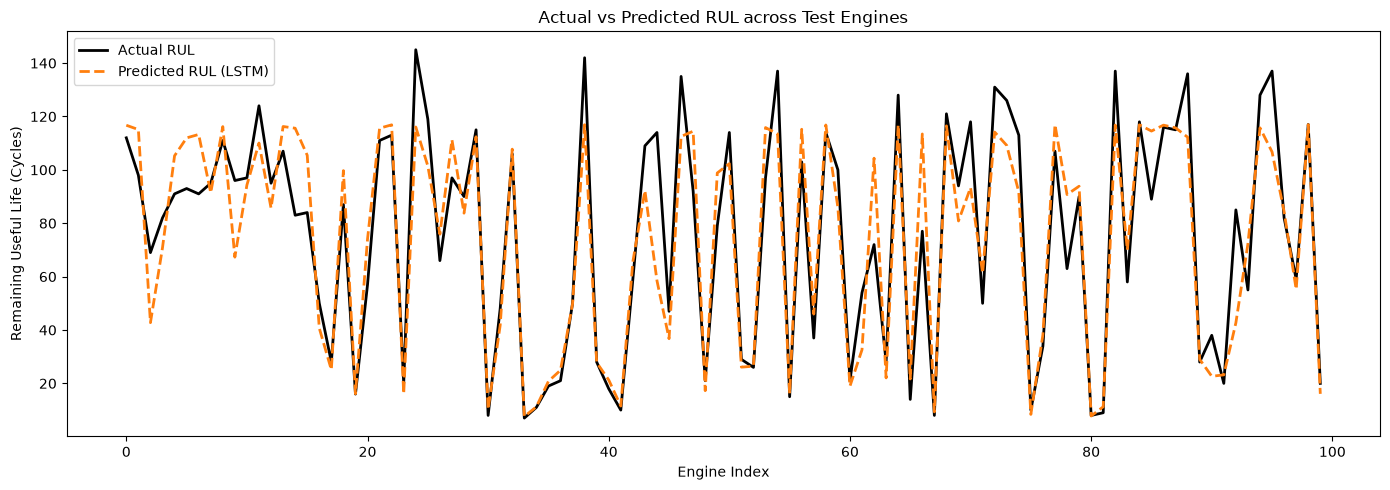

In [8]:
plt.figure(figsize=(14, 5))
plt.plot(y_test_true, label='Actual RUL', color='black', lw=2)
plt.plot(lstm_preds, label='Predicted RUL (LSTM)', color='tab:orange', linestyle='--', lw=2)
plt.title("Actual vs Predicted RUL across Test Engines")
plt.xlabel("Engine Index")
plt.ylabel("Remaining Useful Life (Cycles)")
plt.legend()
plt.tight_layout()
plt.show()

In [9]:
import joblib

# Save scaler and feature column list
joblib.dump(scaler, 'scaler.joblib')
joblib.dump(feature_cols, 'feature_cols.joblib')
print("Scaler and feature list saved successfully!")

Scaler and feature list saved successfully!
